# Simple 1D Kernel Density Estimation: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/neighbors/plot_kde_1d.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/neighbors/plot_kde_1d.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:**
1. Tophat and Gaussian `KernelDensity(bandwidth=0.75)` on 20 bimodal points, `score_samples` on 1000 plotting points.
2. All six kernels fitted on a single point at 0 with the default bandwidth.
3. Gaussian, tophat and Epanechnikov KDEs (`bandwidth=0.5`) on 100 bimodal points.

**Beyond the gallery:** `score`, `bandwidth_`, the Scott/Silverman bandwidth rules, the explicit `kd_tree`/`ball_tree`
backends, weighted fitting, seeded `sample` (the bandwidth search and sampling pattern of
`plot_digits_kde_sampling.py`, on the 1-D data instead of downloaded-free digits+PCA), `GridSearchCV` over the
bandwidth with the KDE's own `score`, keyword `set_params` + refit, and `clone`.

**Adaptations:**
- The seeded `np.random` draws are generated by the official code in Python and shared.
- `bandwidth="scott"` / `"silverman"` is spelled `bandwidth_rule="scott"` in Moxie's typed constructor (documented in
  `families/neighbors/docs/estimators.md`).
- `score_samples` returns Float64 in both libraries.
- `X_src = np.zeros((1, 1))` is constructed in Mojo: the shared notebook loader cannot load a (1, 1) array
  (NuMojo's `array(data=...)` drops every unit dimension; notebook-support issue, not a neighbors one).
- The search adapter passes an ignored all-zero target, because Moxie search adapters are supervised-shaped;
  the scorer is `KernelDensity.score`, as sklearn uses for an unsupervised estimator without `scoring`.

**Determinism:** deterministic. `sample(random_state=0)` uses the same MT19937 stream and draw order in both libraries
(the family's documented contract), so samples are compared numerically too.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("neighbors/plot_kde_1d")

## 1. scikit-learn (Python reference)

The official code (figures kept small), then the extra reference values.

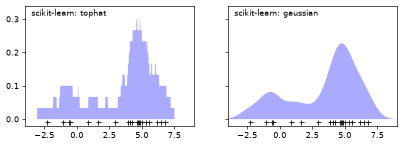

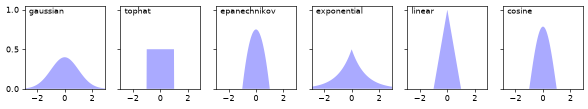

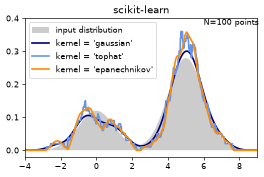

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from sklearn.neighbors import KernelDensity

# Plot the progression of histograms to kernels
np.random.seed(1)
N = 20
X = np.concatenate(
    (np.random.normal(0, 1, int(0.3 * N)), np.random.normal(5, 1, int(0.7 * N)))
)[:, np.newaxis]
X_plot = np.linspace(-5, 10, 1000)[:, np.newaxis]
X20, X_plot20 = X, X_plot
sk = {}
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 2.6), dpi=60)
for axi, kernel in zip(ax, ["tophat", "gaussian"]):
    kde = KernelDensity(kernel=kernel, bandwidth=0.75).fit(X)
    log_dens = kde.score_samples(X_plot)
    sk["p1_" + kernel] = log_dens
    axi.fill(X_plot[:, 0], np.exp(log_dens), fc="#AAAAFF")
    axi.text(-3.5, 0.31, f"scikit-learn: {kernel}")
    axi.plot(X[:, 0], np.full(X.shape[0], -0.01), "+k")
    axi.set_xlim(-4, 9); axi.set_ylim(-0.02, 0.34)
plt.show()

# Plot all available kernels
X_plot_k = np.linspace(-6, 6, 1000)[:, None]
X_src = np.zeros((1, 1))
kernels6 = ["gaussian", "tophat", "epanechnikov", "exponential", "linear", "cosine"]
fig, ax = plt.subplots(1, 6, sharex=True, sharey=True, figsize=(12, 1.8), dpi=60)
for i, kernel in enumerate(kernels6):
    log_dens = KernelDensity(kernel=kernel).fit(X_src).score_samples(X_plot_k)
    sk["p2_" + kernel] = log_dens
    ax[i].fill(X_plot_k[:, 0], np.exp(log_dens), "-k", fc="#AAAAFF")
    ax[i].text(-2.6, 0.95, kernel); ax[i].set_ylim(0, 1.05); ax[i].set_xlim(-2.9, 2.9)
plt.show()

# Plot a 1D density example
N = 100
np.random.seed(1)
X = np.concatenate(
    (np.random.normal(0, 1, int(0.3 * N)), np.random.normal(5, 1, int(0.7 * N)))
)[:, np.newaxis]
X_plot = np.linspace(-5, 10, 1000)[:, np.newaxis]
true_dens = 0.3 * norm(0, 1).pdf(X_plot[:, 0]) + 0.7 * norm(5, 1).pdf(X_plot[:, 0])
fig, ax = plt.subplots(figsize=(5, 3), dpi=60)
ax.fill(X_plot[:, 0], true_dens, fc="black", alpha=0.2, label="input distribution")
for color, kernel in zip(["navy", "cornflowerblue", "darkorange"], ["gaussian", "tophat", "epanechnikov"]):
    kde = KernelDensity(kernel=kernel, bandwidth=0.5).fit(X)
    log_dens = kde.score_samples(X_plot)
    sk["p3_" + kernel] = log_dens
    ax.plot(X_plot[:, 0], np.exp(log_dens), color=color, lw=2, linestyle="-", label="kernel = '{0}'".format(kernel))
ax.text(6, 0.38, "N={0} points".format(N)); ax.legend(loc="upper left")
ax.set_xlim(-4, 9); ax.set_ylim(-0.02, 0.4); ax.set_title("scikit-learn")
plt.show()

In [3]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold

extra = {}
kde = KernelDensity(kernel="gaussian", bandwidth=0.5).fit(X)
extra["score"] = kde.score(X_plot)
for rule in ("scott", "silverman"):
    k = KernelDensity(bandwidth=rule).fit(X)
    extra["bw_" + rule] = k.bandwidth_
    extra["ll_" + rule] = k.score_samples(X_plot)
for algorithm in ("kd_tree", "ball_tree"):
    extra["algo_" + algorithm] = KernelDensity(kernel="epanechnikov", bandwidth=0.5, algorithm=algorithm).fit(X).score_samples(X_plot)
weights = np.linspace(0.5, 2.0, len(X))
extra["weighted"] = KernelDensity(bandwidth=0.5).fit(X, sample_weight=weights).score_samples(X_plot)
extra["sample_gaussian"] = KernelDensity(bandwidth=0.5).fit(X).sample(8, random_state=0)
extra["sample_tophat"] = KernelDensity(kernel="tophat", bandwidth=0.5).fit(X).sample(8, random_state=0)
kde.set_params(kernel="exponential", bandwidth=0.3)
extra["set_params"] = kde.fit(X).score_samples(X_plot)
print("clone of fitted KDE is unfitted:", not hasattr(clone(kde), "tree_"))

# Bandwidth search of plot_digits_kde_sampling.py, on the 1-D sample.
bandwidths = np.logspace(-1, 1, 20)
grid = GridSearchCV(KernelDensity(), {"bandwidth": bandwidths}, cv=KFold(5)).fit(X[np.random.RandomState(0).permutation(N)])
extra["search_mean"] = grid.cv_results_["mean_test_score"]
extra["search_best"] = np.array([grid.best_params_["bandwidth"], grid.best_score_])
print("best bandwidth: {0:.4f}".format(grid.best_params_["bandwidth"]), "| scott:", round(extra["bw_scott"], 4))
nb.share(X20=X20, X_plot20=X_plot20, X_src=X_src, X_plot_k=X_plot_k, X100=X, X_plot=X_plot, weights=weights,
         bandwidths=bandwidths, X_shuffled=X[np.random.RandomState(0).permutation(N)])

clone of fitted KDE is unfitted: True
best bandwidth: 0.5456 | scott: 0.3981


## 2. Moxie (native Mojo)

In [4]:
%%mojo kde
from numojo import NDArray, Shape
from moxie.base import clone
from moxie.neighbors import KernelDensity
from moxie_nb_io import load, save, save_floats


def main() raises:
    var X20 = load("X20")
    var X_plot20 = load("X_plot20")
    for kernel in ["tophat", "gaussian"]:
        var kde = KernelDensity(kernel=String(kernel), bandwidth=0.75)
        _ = kde.fit(X20)
        save("p1_" + String(kernel), kde.score_samples(X_plot20))
    # X_src = np.zeros((1, 1)) is built here: the notebook loader (NuMojo array(data=...)) collapses a
    # (1, 1) array to rank 0.
    var X_src = NDArray[DType.float64](Shape(1, 1))
    X_src.unsafe_set(0, 0.0)
    var X_plot_k = load("X_plot_k")
    for kernel in ["gaussian", "tophat", "epanechnikov", "exponential", "linear", "cosine"]:
        var kde = KernelDensity(kernel=String(kernel))
        _ = kde.fit(X_src)
        save("p2_" + String(kernel), kde.score_samples(X_plot_k))
    var X = load("X100")
    var X_plot = load("X_plot")
    for kernel in ["gaussian", "tophat", "epanechnikov"]:
        var kde = KernelDensity(kernel=String(kernel), bandwidth=0.5)
        _ = kde.fit(X)
        save("p3_" + String(kernel), kde.score_samples(X_plot))

    var kde = KernelDensity(kernel="gaussian", bandwidth=0.5)
    _ = kde.fit(X)
    save_floats("score", [kde.score(X_plot)])
    for rule in ["scott", "silverman"]:
        var k = KernelDensity(bandwidth_rule=String(rule))
        _ = k.fit(X)
        save_floats("bw_" + String(rule), [k.bandwidth_])
        save("ll_" + String(rule), k.score_samples(X_plot))
    for algorithm in ["kd_tree", "ball_tree"]:
        var k = KernelDensity(kernel="epanechnikov", bandwidth=0.5, algorithm=String(algorithm))
        _ = k.fit(X)
        save("algo_" + String(algorithm), k.score_samples(X_plot))
    var weighted = KernelDensity(bandwidth=0.5)
    _ = weighted.fit(X, sample_weight=load("weights"))
    save("weighted", weighted.score_samples(X_plot))
    var g = KernelDensity(bandwidth=0.5)
    _ = g.fit(X)
    save("sample_gaussian", g.sample(8, random_state=0))
    var t = KernelDensity(kernel="tophat", bandwidth=0.5)
    _ = t.fit(X)
    save("sample_tophat", t.sample(8, random_state=0))
    _ = kde.set_params(kernel="exponential", bandwidth=0.3)
    _ = kde.fit(X)
    save("set_params", kde.score_samples(X_plot))
    var fresh = clone(kde)
    print("clone of fitted KDE is unfitted:", not fresh.__sklearn_is_fitted__(), "| original fitted:", kde.__sklearn_is_fitted__())

clone of fitted KDE is unfitted: True | original fitted: True


`GridSearchCV` over `bandwidth`, scored by `KernelDensity.score` (the pattern of `plot_digits_kde_sampling.py`).

In [5]:
%%mojo kde_search
from numojo import NDArray, Shape
from moxie.model_selection import GridSearchCV, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer
from moxie.model_selection._split import _rows
from moxie.neighbors import KernelDensity
from moxie_nb_io import load, save, save_floats

comptime Dense = NDArray[DType.float64]


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct LogLikelihood(SearchScorer):
    # sklearn's default for an unsupervised estimator without `scoring`: estimator.score(X).
    comptime Estimator = KernelDensity[]
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: KernelDensity[], X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X)


struct BandwidthSearch(SearchAdapter):
    comptime Scorer = LogLikelihood
    comptime Value = Float64

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: KernelDensity[], X: Dense, y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(X)

    def configure(self, mut estimator: KernelDensity[], params: Dict[String, Float64]) raises:
        for key in params.keys():
            if key != "bandwidth":
                raise Error("ValueError: this adapter tunes only bandwidth")
        _ = estimator.set_params(bandwidth=params["bandwidth"])

    def default_scorer(self) raises -> LogLikelihood:
        return LogLikelihood()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(X.shape[0])


def main() raises:
    var X = load("X_shuffled")
    var bandwidths = load("bandwidths")
    var grid = Dict[String, List[Float64]]()
    var values = List[Float64]()
    for i in range(bandwidths.size):
        values.append(Float64(bandwidths.unsafe_get(i)))
    grid["bandwidth"] = values^
    var ignored = NDArray[DType.float64](Shape(X.shape[0]))
    for i in range(X.shape[0]):
        ignored.unsafe_set(i, 0)
    var search = GridSearchCV[BandwidthSearch](KernelDensity(), grid, BandwidthSearch(), cv=kfold(X.shape[0]))
    search.fit(X, ignored, None, None)
    save("search_mean", search.cv_results_().mean_test_score)
    save_floats("search_best", [search.best_params_()["bandwidth"], search.best_score_()])

## 3. Side by side and parity

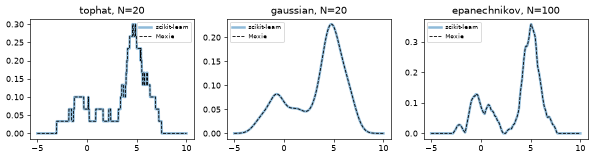

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/notebooks/_support/moxie_nb.py:141: RuntimeWarning: invalid value encountered in subtract
  diff = np.abs(sk64 - mx64)


check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
N=20 bandwidth=0.75 tophat: score_samples,PASS,"(1000,)","(1000,)",4.44e-16,3.69e-16,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
N=20 bandwidth=0.75 gaussian: score_samples,PASS,"(1000,)","(1000,)",3.55e-15,5.99e-16,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
"single point, gaussian: score_samples",PASS,"(1000,)","(1000,)",0,0,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
"single point, tophat: score_samples",PASS,"(1000,)","(1000,)",0,0,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
"single point, epanechnikov: score_samples",PASS,"(1000,)","(1000,)",2.22e-16,1.7e-16,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
"single point, exponential: score_samples",PASS,"(1000,)","(1000,)",4.44e-16,2.2e-16,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
"single point, linear: score_samples",PASS,"(1000,)","(1000,)",2.22e-16,2.16e-16,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
"single point, cosine: score_samples",PASS,"(1000,)","(1000,)",8.88e-16,4.6e-16,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
N=100 bandwidth=0.5 gaussian: score_samples,PASS,"(1000,)","(1000,)",7.11e-15,2.48e-15,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50
N=100 bandwidth=0.5 tophat: score_samples,PASS,"(1000,)","(1000,)",8.88e-16,5.01e-16,"rtol=0, atol=1e-13",,exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log (within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50


In [6]:
mx = nb.results["kde"]
fig, ax = plt.subplots(1, 3, figsize=(12, 2.6), dpi=60)
for axi, (k, title) in zip(ax, [("p1_tophat", "tophat, N=20"), ("p1_gaussian", "gaussian, N=20"), ("p3_epanechnikov", "epanechnikov, N=100")]):
    grid_x = X_plot20[:, 0] if k.startswith("p1") else X_plot[:, 0]
    axi.plot(grid_x, np.exp(sk[k]), lw=3, alpha=0.5, label="scikit-learn")
    axi.plot(grid_x, np.exp(mx[k]), "k--", lw=1, label="Moxie")
    axi.set_title(title); axi.legend(fontsize=7)
plt.show()
moxie_nb.side_by_side(sklearn=dict(scott=extra["bw_scott"], silverman=extra["bw_silverman"], score=extra["score"]),
                      moxie=dict(scott=float(mx["bw_scott"][0]), silverman=float(mx["bw_silverman"][0]), score=float(mx["score"][0])))
KDE = ("exact (atol=rtol=0) kernel sums in Float64 with log-sum-exp over up to 100 points; Numax fdlibm exp/log "
       "(within one ulp of glibc) and summation order leave a few ulps on log densities of order 1-50")
for k in ("p1_tophat", "p1_gaussian"):
    nb.compare(f"N=20 bandwidth=0.75 {k[3:]}: score_samples", sk[k], mx[k], rtol=0, atol=1e-13, reason=KDE)
for kernel in kernels6:
    nb.compare(f"single point, {kernel}: score_samples", sk["p2_" + kernel], mx["p2_" + kernel], rtol=0, atol=1e-13, reason=KDE)
for kernel in ("gaussian", "tophat", "epanechnikov"):
    nb.compare(f"N=100 bandwidth=0.5 {kernel}: score_samples", sk["p3_" + kernel], mx["p3_" + kernel], rtol=0, atol=1e-13, reason=KDE)
nb.compare("score (sum of 1000 log densities)", np.array([extra["score"]]), mx["score"], rtol=1e-14, atol=0,
           reason="sum of 1000 log densities, each within a few ulps")
for rule in ("scott", "silverman"):
    nb.compare(f"bandwidth_ ({rule})", np.array([extra["bw_" + rule]]), mx["bw_" + rule], rtol=1e-15, atol=0,
               reason="n**(-1/(d+4)) as fdlibm exp(log(n) * -1/(d+4)): a few ulps at most")
    nb.compare(f"score_samples with bandwidth={rule!r}", extra["ll_" + rule], mx["ll_" + rule], rtol=0, atol=1e-13, reason=KDE)
for algorithm in ("kd_tree", "ball_tree"):
    nb.compare(f"algorithm={algorithm!r}, epanechnikov", extra["algo_" + algorithm], mx["algo_" + algorithm], rtol=0, atol=1e-13, reason=KDE)
nb.compare("weighted fit (sample_weight)", extra["weighted"], mx["weighted"], rtol=0, atol=1e-13, reason=KDE)
nb.compare("sample(8, random_state=0), gaussian", extra["sample_gaussian"], mx["sample_gaussian"], rtol=1e-12, atol=1e-12,
           reason="same MT19937 stream and draw order; Box-Muller/inversion rounding only")
nb.compare("sample(8, random_state=0), tophat", extra["sample_tophat"], mx["sample_tophat"], rtol=1e-9, atol=1e-9,
           reason="same draw order; the tophat radius uses a gammainc inverse whose native series differs from SciPy "
                  "in the last digits (documented 9.1e-10 maximum in kde-sampling.md)")
nb.compare("set_params(kernel='exponential', bandwidth=0.3) + refit", extra["set_params"], mx["set_params"], rtol=0, atol=1e-13, reason=KDE)
ms = nb.results["kde_search"]
nb.compare("GridSearchCV mean_test_score (20 bandwidths)", extra["search_mean"], ms["search_mean"].ravel(), rtol=1e-13, atol=0,
           reason="held-out log-likelihood sums of 20 terms, each within a few ulps")
nb.compare("GridSearchCV best (bandwidth, score)", extra["search_best"], ms["search_best"], rtol=1e-13, atol=0, reason="as above")
nb.note("bandwidth='scott'", "ADAPTED", "spelled bandwidth_rule='scott' in the typed constructor (estimators.md)")
nb.note("unsupervised search", "ADAPTED", "Moxie search adapters are supervised-shaped; an ignored all-zero target is passed")
nb.report()
nb.assert_parity()